In [1]:
import jax
import os

In [2]:
import sys
sys.path.append("../")

%load_ext autoreload
%autoreload 2

import pulse_simulator as ps

/home/andy/Documents/Research/pulse-simulator/.venv/lib/python3.10/site-packages/qiskit_dynamics/dispatch/backends/jax.py:34: UserWarning: The functionality in the perturbation module of Qiskit Dynamics requires a JAX version <= 0.4.6, due to a bug in JAX versions > 0.4.6. For versions 0.4.4, 0.4.5, and 0.4.6, using the perturbation module functionality requires setting os.environ['JAX_JIT_PJIT_API_MERGE'] = '0' before importing JAX or Dynamics.
  warnings.warn(


In [3]:
from datetime import datetime
import functools
import itertools
import logging
import numpy as np
import pickle as pkl

import qiskit as qk
from qiskit import pulse
import qiskit_aer
import qiskit.providers.fake_provider as qk_fp
import qiskit_dynamics as qk_d

import qutip as qt
import re 
from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm, logm
from tqdm import tqdm
import warnings

import matplotlib.pyplot as plt

In [4]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

backend = qk_fp.FakeManila()
dt = backend.configuration().dt * ns
desired_1qb_duration = 225  # dt
desired_2qb_duration = 225 * 4  # dt

# Gate time in SI units (granularity restriction)
duration_1qb = ps.qiskit_closest_multiple_of_16(desired_1qb_duration * dt / ns, backend)
duration_2qb = ps.qiskit_closest_multiple_of_16(desired_2qb_duration * dt / ns, backend)

# Calibrate

In [5]:
# Load shapes
fname_1qb = "../pico-pulses/saved-pulses-2024-02-16/a_single_qubit_gateset_R1e-5.csv"
pico_a = ps.from_csv(fname_1qb)
pico_a = np.vstack([pico_a, 1.0 * np.ones(pico_a.shape[1])])

names_1qb = ["X1", "X2", "SX1", "SX2", "I1", "I2"]
angles_1qb = [1.5 * np.pi, 0.5 * np.pi, 1.25 * np.pi, 0.25 * np.pi, 0.2, 0.0]

In [6]:
cal_1qb_robust = ps.calibrate_gateset(
    gateset=pico_a,
    names=names_1qb,
    angles=angles_1qb,
    duration=duration_1qb,
    dt=dt,
)

Storing symbolic pulses...
Adjusting X1 by amplitude 0.20 for angle 1.50π
Adjusting X2 by amplitude 0.20 for angle 0.50π
Adjusting SX1 by amplitude 0.20 for angle 1.25π
Adjusting SX2 by amplitude 0.20 for angle 0.25π
Zero area signal. Adjusting I1 by amplitude 0.20 (using provided angle).
Adjusting I2 by amplitude 0.00 for angle 0.00π


In [7]:
cal_1qb_default = ps.default_single_qubit_gateset(
    names_1qb,
    duration_1qb,
    dt,
)

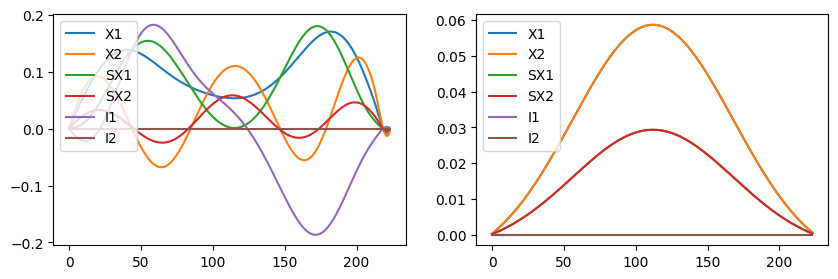

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

ax = axes[0]
for i, (k, v) in enumerate(cal_1qb_robust.items()):
    ax.plot(ps.get_samples(v).real, label=names_1qb[i])
ax.legend(loc="upper left")

ax = axes[1]
for i, (k, v) in enumerate(cal_1qb_default.items()):
    ax.plot(ps.get_samples(v).real, label=names_1qb[i])
ax.legend(loc="upper left")

In [9]:
# Load shapes
def fname(k):
    return f"../pico-pulses/saved-pulses-2024-01-16/a_two_qubit_{k}.csv"

base_2qb = {k: ps.from_csv(fname(k))[0] for k in ["default", "robust"]}
robust_2qb = 2 * [base_2qb["robust"]]
default_2qb = 2 * [base_2qb["default"]]
names_2qb = ["+", "-"]

In [10]:
cal_2qb_robust = ps.calibrate_gateset(
    gateset=robust_2qb,
    names=names_2qb,
    angles=[0.125 * np.pi, -0.125 * np.pi],
    duration=duration_2qb,
    dt=dt,
    samples=32,
)

Storing symbolic pulses...
Adjusting + by amplitude 0.30 for angle 0.12π
Adjusting - by amplitude-0.30 for angle-0.12π


In [11]:
cal_2qb_default = ps.calibrate_gateset(
    gateset=default_2qb,
    names=names_2qb,
    angles=[0.125 * np.pi, -0.125 * np.pi],
    duration=duration_2qb,
    dt=dt,
    samples=32,
)

Storing symbolic pulses...
Adjusting + by amplitude 0.30 for angle 0.12π
Adjusting - by amplitude-0.30 for angle-0.12π


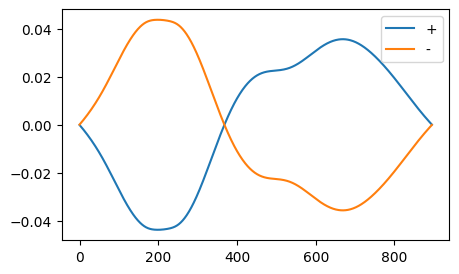

In [12]:
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
for i, (k, v) in enumerate(cal_2qb_robust.items()):
    ax.plot(ps.get_samples(v).real, label=names_2qb[i])
ax.legend(loc="upper right")

# Build circuit

In [13]:
registers = [0, 1]
coupling_map = ps.backend_edges(backend)

# xy4_depth = 40
xy4_depth = 2

In [14]:
def prepare_state(circ, registers):
    [circ.h(r) for r in registers]

def apply_xy4(circ, q, reverse=False):
    if reverse:
        circ.y(q)
        circ.x(q)
        circ.y(q)
        circ.x(q)
    else:
        circ.x(q)
        circ.y(q)
        circ.x(q)
        circ.y(q)

def apply_simultaneous_xy4(circ, q0, q1):
    apply_xy4(circ, q0)
    apply_xy4(circ, q1, reverse=True)

In [15]:
circ = qk.QuantumCircuit(2, 2)

prepare_state(circ, registers)
for _ in range(xy4_depth):
    apply_simultaneous_xy4(circ, 0, 1)
prepare_state(circ, registers)

# circ.draw('mpl')

In [16]:
mb = ps.MomentBuilder(
    coupling_map=ps.backend_edges(backend),
    gate_durations={1: duration_1qb, 2: duration_2qb}
)

moments = mb.build_moments(
    circ, 
    optimization_level=0, 
    
)

Building schedule with 21 moments. 
	 Qubit gateset: dict_keys(['X1', 'X2', 'SX1', 'SX2', 'I1', 'I2'])
	 CR gateset: dict_keys(['+', '-'])
	 Registers: [0, 1]
	 Insert identities: True


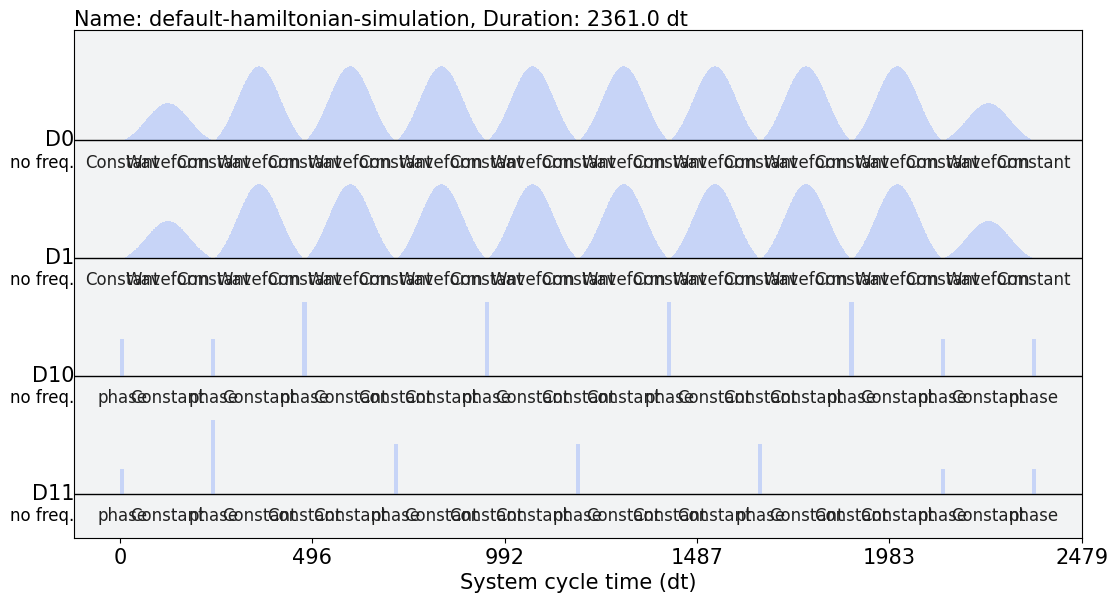

In [17]:
sched = ps.build_pulse_schedule(
    moments,
    qubit_gates=cal_1qb_default,
    cr_gates=cal_2qb_default,
    registers=registers,
    backend=backend,
    name="default-hamiltonian-simulation",
    dt=dt,
    insert_identities=True,
    verbose=True
)

robust_sched = ps.build_pulse_schedule(
    moments,
    qubit_gates=cal_1qb_robust,
    cr_gates=cal_2qb_robust,
    registers=registers,
    backend=backend,
    name="robust-hamiltonian-simulation",
    dt=dt,
    insert_identities=True,
    verbose=False
)

# Check durations
assert robust_sched.duration == sched.duration

# Would be nice to disable phase channels when plotting
sched.draw()

/home/andy/Documents/Research/pulse-simulator/.venv/lib/python3.10/site-packages/qiskit/visualization/circuit/matplotlib.py:266: FutureWarning: The default matplotlib drawer scheme will be changed to "iqp" in a following release. To silence this warning, specify the current default explicitly as style="clifford", or the new default as style="iqp".
  self._style, def_font_ratio = load_style(self._style)


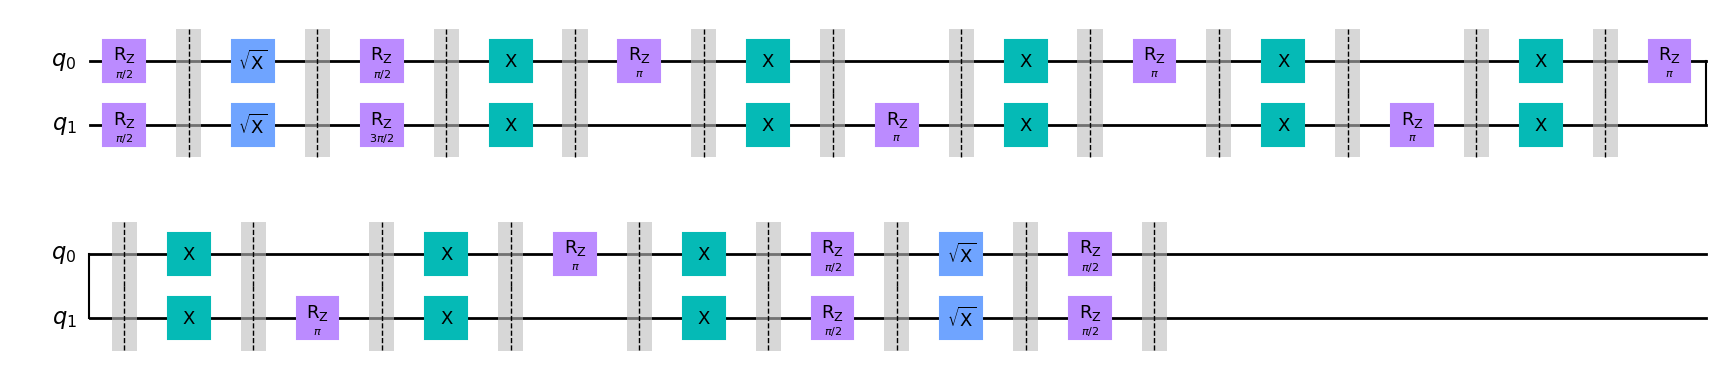

In [18]:
circ2 = ps.build_circuit(moments, registers, insert_identities=False, barriers=True)
circ2.draw('mpl')

# Solvers

In [19]:
# # NOTE: If the Rabi rates are True, you have to calibrate!
# cvars = ps.backend_simulation_vars(backend, rabi=False, units=Units)

# # Change T1 and T2 to match Eagle processors like Sherbrooke
# for k, v in cvars.items():
#     if "t1" in k:
#         cvars[k] = 250 / μs * ns
#     if "t2" in k:
#         cvars[k] = 150 / μs * ns

In [20]:
solver_r0 = ps.build_solver(
    registers,
    backend,
    include_crosstalk=False,
    include_dissipation=False
)

solver_rx0 = ps.build_solver(
    registers,
    backend,
    include_crosstalk=True,
    include_dissipation=False
)

solver_rx0 = ps.build_solver(
    registers,
    backend,
    include_crosstalk=True,
    include_dissipation=True
)

In [22]:
# for m in moments:
#     if ps.get_moment_case(m) == "phase":
#         for q in registers:
#             if q not in m.keys():
#                 m[q] = 0.0

# Runs

## Timesteps

In [30]:
# measure after each non-phase moment
measure_times = dt * np.cumsum(
    ps.durations_of_moments(moments, duration_1qb, duration_2qb)
)

#[[ps.get_moment_case(m) != "phase" for m in moments]]
# and at the end time...
# measure_times = np.append(measure_times, sched.duration * dt)


# targets at measure times
Uts = []
for i, m in enumerate(moments):
    # if ps.get_moment_case(m) != "phase":
    Uts.append(ps.build_operator(moments[0:i+1], registers))
# and at the end time...
# Uts.append(ps.build_operator(moments[:-1], registers))

# Target
target = ps.build_operator(moments[:-1], registers)

In [71]:
# data = np.isclose((measure_times[1:] - measure_times[:-1] ) / dt, 1)
# data[::2]
# data[1::2]


In [126]:
test_sched = ps.build_pulse_schedule(
    [{0: np.pi / 2, 1: np.pi / 4}],
    qubit_gates=cal_1qb_default,
    cr_gates=cal_2qb_default,
    registers=registers,
    backend=backend,
    name="test",
    dt=dt,
    insert_identities=True,
    verbose=True
)

Building schedule with 1 moments. 
	 Qubit gateset: dict_keys(['X1', 'X2', 'SX1', 'SX2', 'I1', 'I2'])
	 CR gateset: dict_keys(['+', '-'])
	 Registers: [0, 1]
	 Insert identities: True


In [127]:
y0 = ps.qiskit_identity_operator(len(registers))

solver_r0.model.evaluation_mode = "dense"
res_0 = solver_r0.solve(
    t_span=[0.0, sched.duration * dt],
    t_eval=[sched.duration * dt],
    y0=y0,
    signals=test_sched,
    atol=1e-9,
    rtol=1e-9,
    method="jax_odeint",
)

In [129]:
# θ1 + θ2
θ = (1j * logm(res_0.y[-1].data)).real
θ

array([[-0.45160464,  0.        ,  0.        ,  0.        ],
       [ 0.        , -1.94386022, -0.        ,  0.        ],
       [ 0.        ,  0.        ,  1.94386022,  0.        ],
       [ 0.        ,  0.        ,  0.        ,  0.45160464]])

In [131]:
np.mod(θ[0,0] / np.pi, 2)

1.8562497769297153

In [117]:
DURATION_PHASE_GATE = 11

In [118]:
test = ps.constant_envelope(
    DURATION_PHASE_GATE,
    angle=np.pi,
    name="phase",
    dt=dt,
)

In [119]:
np.trapz(ps.get_samples(test).real, dx=dt) / np.pi

1.0

array([1.17809725+0.j, 1.17809725+0.j, 1.17809725+0.j, 1.17809725+0.j])

## Without decoherence

In [35]:
y0 = ps.qiskit_identity_operator(len(registers))
# y0 = ps.qiskit_ground_state(len(registers), open=False)

labels = ["robust",  "default"]
all_schedules = [robust_sched, sched]

# ==========

solver_rx0.model.evaluation_mode = "dense"
res_x0 = solver_rx0.solve(
    t_span=[0.0, sched.duration * dt],
    t_eval=measure_times,
    y0=y0,
    signals=all_schedules,
    atol=1e-9,
    rtol=1e-9,
    method="jax_odeint",
)

# Compute fidelity (we can use our circuit to compute the target)
target = qk.quantum_info.Operator(ps.build_circuit(moments, registers))
# y_target = y0.evolve(target)

for i, ell in enumerate(labels):
    print(f"\tInfidelity of {ell}: ", 1 - qk.quantum_info.process_fidelity(res_x0[i].y[-1], target))

# for i, ell in enumerate(labels):
#     print(f"\tInfidelity of {ell} schedule: {1 - qk.quantum_info.state_fidelity(res_x0[i].y[-1], y_target)}")

	Infidelity of robust:  2.6381369522265885e-07
	Infidelity of default:  0.0024764497465830093


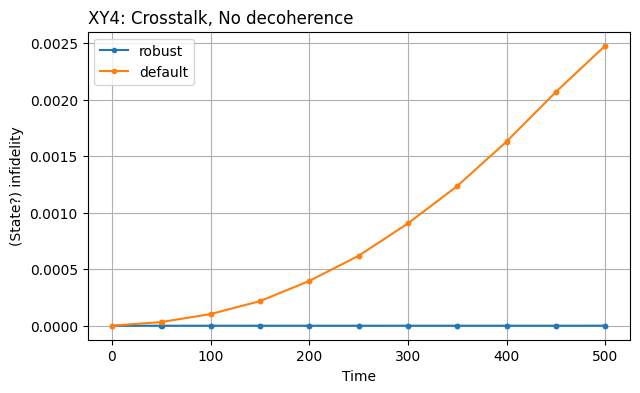

In [37]:
fig, axes = plt.subplots(1, figsize=[7, 4])
axes = axes if isinstance(axes, np.ndarray) else [axes]

ax = axes[0]
ax.set_title("XY4: Crosstalk, No decoherence", loc='left')

for i, res in enumerate(res_x0):
    infids = []
    for r, t in zip(res.y, Uts):
        infids.append(1 - qk.quantum_info.process_fidelity(r, t))
        # infids.append(1 - qk.quantum_info.state_fidelity(r, y0.evolve(t)))
    ax.plot(measure_times, infids, label=labels[i], marker=".")

ax.set_xlabel("Time")
ax.legend(loc="upper left")
# ax.set_yscale("log")
ax.set_ylabel("(State?) infidelity")
ax.grid(True)

### Aside

In [27]:
infids = np.array(infids)
np.argmax(infids[1:] - infids[:-1])

55

In [28]:
np.round(res.y[54:57], 1)

array([[ 0.1+0.5j,  0.1-0.5j, -0.1+0.5j, -0.1-0.5j],
       [ 0.1+0.5j,  0.1-0.5j, -0.1+0.5j, -0.1-0.5j],
       [ 0.1+0.5j,  0.1-0.5j, -0.1+0.5j, -0.1-0.5j]])

In [29]:
np.round([phi*y0.evolve(t) for phi, t in zip([-1j, 1j, -1], Uts[54:57])], 1)


array([[-0.+0.5j,  0.-0.5j,  0.+0.5j,  0.-0.5j],
       [ 0.+0.5j, -0.-0.5j, -0.+0.5j,  0.-0.5j],
       [-0.+0.5j,  0.+0.5j, -0.+0.5j, -0.+0.5j]])

In [30]:
for a,b in zip(res.y[54:58], [y0.evolve(t) for t in Uts[54:58]]):
    print(qk.quantum_info.state_fidelity(a, b))

0.9808416782486684
0.9787568929754173
2.4449623672025627e-06
2.4449655068560885e-06


In [31]:
moments[52:58]

[{0: 3.141592653589793, 1: 0.0},
 {0: 'X', 1: 'X'},
 {1: 3.141592653589793, 0: 0.0},
 {0: 'X', 1: 'X'},
 {0: 3.141592653589793, 1: 0.0},
 {0: 'X', 1: 'X'}]

In [32]:
qk.quantum_info.state_fidelity(r, y0.evolve(t))

9.848768832106452e-06

## Decoherence

In [33]:
print("Case 2: Crosstalk and Decoherence")

# y0 = ps.qiskit_identity_operator(len(registers), open=True)
y0 = ps.qiskit_ground_state(len(registers), open=True)

labels = ["robust", "default"]
schedules = [robust_sched, sched]

solver_rx.model.evaluation_mode = "dense"
res_x = solver_rx.solve(
    t_span=[0.0, sched.duration * dt],
    t_eval=measure_times,
    y0=y0,
    signals=schedules,
    atol=1e-9,
    rtol=1e-9,
    method="jax_odeint",
)

# Compute fidelity (we can use our circuit to compute the target)
target = qk.quantum_info.Operator(ps.build_circuit(moments, registers))
y_target = y0.evolve(target)

# for i in range(len(res_x)):
#     print(
#         f"\tInfidelity of {labels[i]} schedule: {1 - qk.quantum_info.process_fidelity(res_x[0].y[-1], target)}"
#     )

for i in range(len(res_x)):
    print(
        f"\tInfidelity of {labels[i]} schedule: {1 - qk.quantum_info.state_fidelity(res_x[i].y[-1], y_target)}"
    )

Case 2: Crosstalk and Decoherence
	Infidelity of robust schedule: 0.05170556443742769
	Infidelity of default schedule: 0.5791670224947439


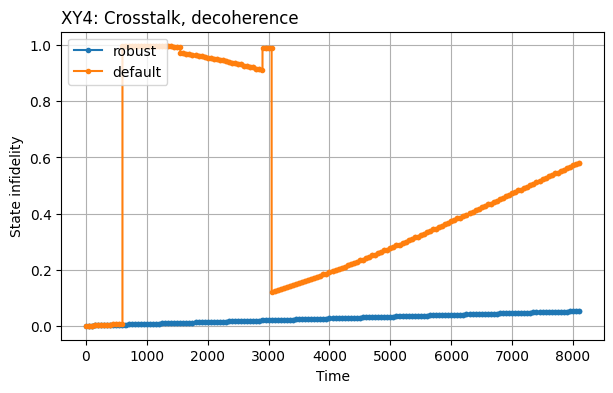

In [34]:
fig, axes = plt.subplots(1, figsize=[7, 4])
axes = axes if isinstance(axes, np.ndarray) else [axes]

ax = axes[0]
ax.set_title("XY4: Crosstalk, decoherence", loc='left')


for i, res in enumerate(res_x):
    infids = []
    for r, t in zip(res.y, Uts):
        infids.append(1 - qk.quantum_info.state_fidelity(r, y0.evolve(t)))
    ax.plot(measure_times, infids, label=labels[i], marker=".")

ax.set_xlabel("Time")
ax.legend(loc="upper left")
# ax.set_yscale("log")
ax.set_ylabel("State infidelity")
ax.grid(True)